# Compare multiple modelling configurations

Load both exported top20_maxbudget.csv files for the same run. Every saved row is retained. Colours identify settling prescriptions throughout. These are optimisation samples, not posterior distributions.


In [1]:
import sys
print(sys.executable)


import pandas as pd
%matplotlib inline

import matplotlib
print("backend:", matplotlib.get_backend())
import matplotlib.pyplot as plt

import corner
import matplotlib.pyplot as plt
from pathlib import Path
import numpy as np


/home/kandrych/venvs/obriy311/bin/python
backend: inline


In [ ]:
BASE_DIR = Path('/fred/oz061/kandrych/smac/1_akke_2zones_wider_tapered/')
RUN_NAME = 'dubrulle'  # Use the same observation combination for both prescriptions.
CSV_PATHS = {
    label: BASE_DIR  / RUN_NAME /label / 'smac_results/after_optimisation/top20_maxbudget.csv'
    for label in ['sed', 'sed_pdi', 'sed_alma', 'sed_interf', 'sed_interf_pdi_alma_full_all', 'sed_interf_pdi_alma_stages']
}
COLORS = {'sed': 'tab:blue', 'sed_pdi': 'tab:orange', 'sed_alma': 'tab:green', 'sed_interf': 'tab:red', 'sed_interf_pdi_alma_full_all': 'tab:purple', 'sed_interf_pdi_alma_stages': 'tab:brown'}
selections = {}
for label, csv_path in CSV_PATHS.items():
    data = pd.read_csv(csv_path)
    data = data.loc[:, ~data.columns.str.startswith('Unnamed:')]
    if data.empty:
        raise ValueError(f'No configurations in {csv_path}')
    data['cost'] = pd.to_numeric(data['cost'], errors='raise')
    if not np.isfinite(data['cost']).all() or data['budget'].nunique() != 1:
        raise ValueError(f'Expected finite costs at one budget: {csv_path}')
    selections[label] = data.sort_values('cost', kind='stable').reset_index(drop=True)
    print(f'{label}: loaded {len(data)} saved configurations from {csv_path}')
results_dir = BASE_DIR / 'comparison' / RUN_NAME / 'top20_plots'
results_dir.mkdir(parents=True, exist_ok=True)
exclude = {'config_id', 'seed', 'budget', 'cost', 'time', 'status',
           'distance_pc', 'zone_1_Rref', 'additional_info'}
common_cols = set.intersection(*(set(data.columns) for data in selections.values()))
param_cols = [c for c in next(iter(selections.values())).columns if c in common_cols and c not in exclude]
combined = pd.concat([data.assign(prescription=label) for label, data in selections.items()], ignore_index=True)
summary = combined.groupby('prescription')['cost'].agg(['count', 'min', 'median', 'max'])
display(summary)
summary.to_csv(results_dir / 'cost_summary.csv')


FileNotFoundError: [Errno 2] No such file or directory: '/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1/seed1/sed/smac_results/after_optimisation/top20_maxbudget.csv'

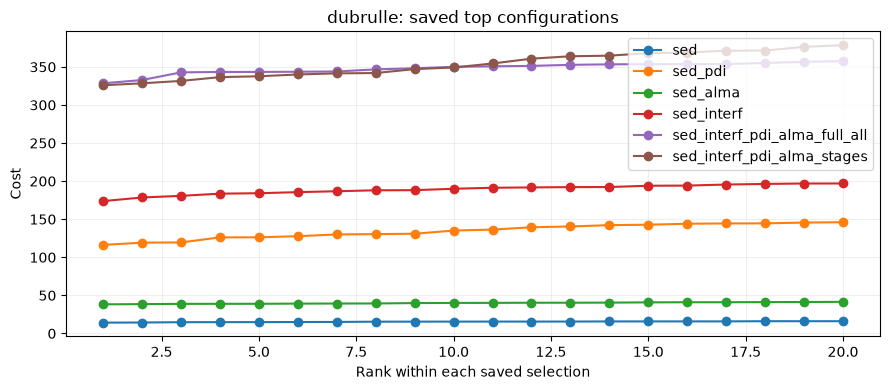

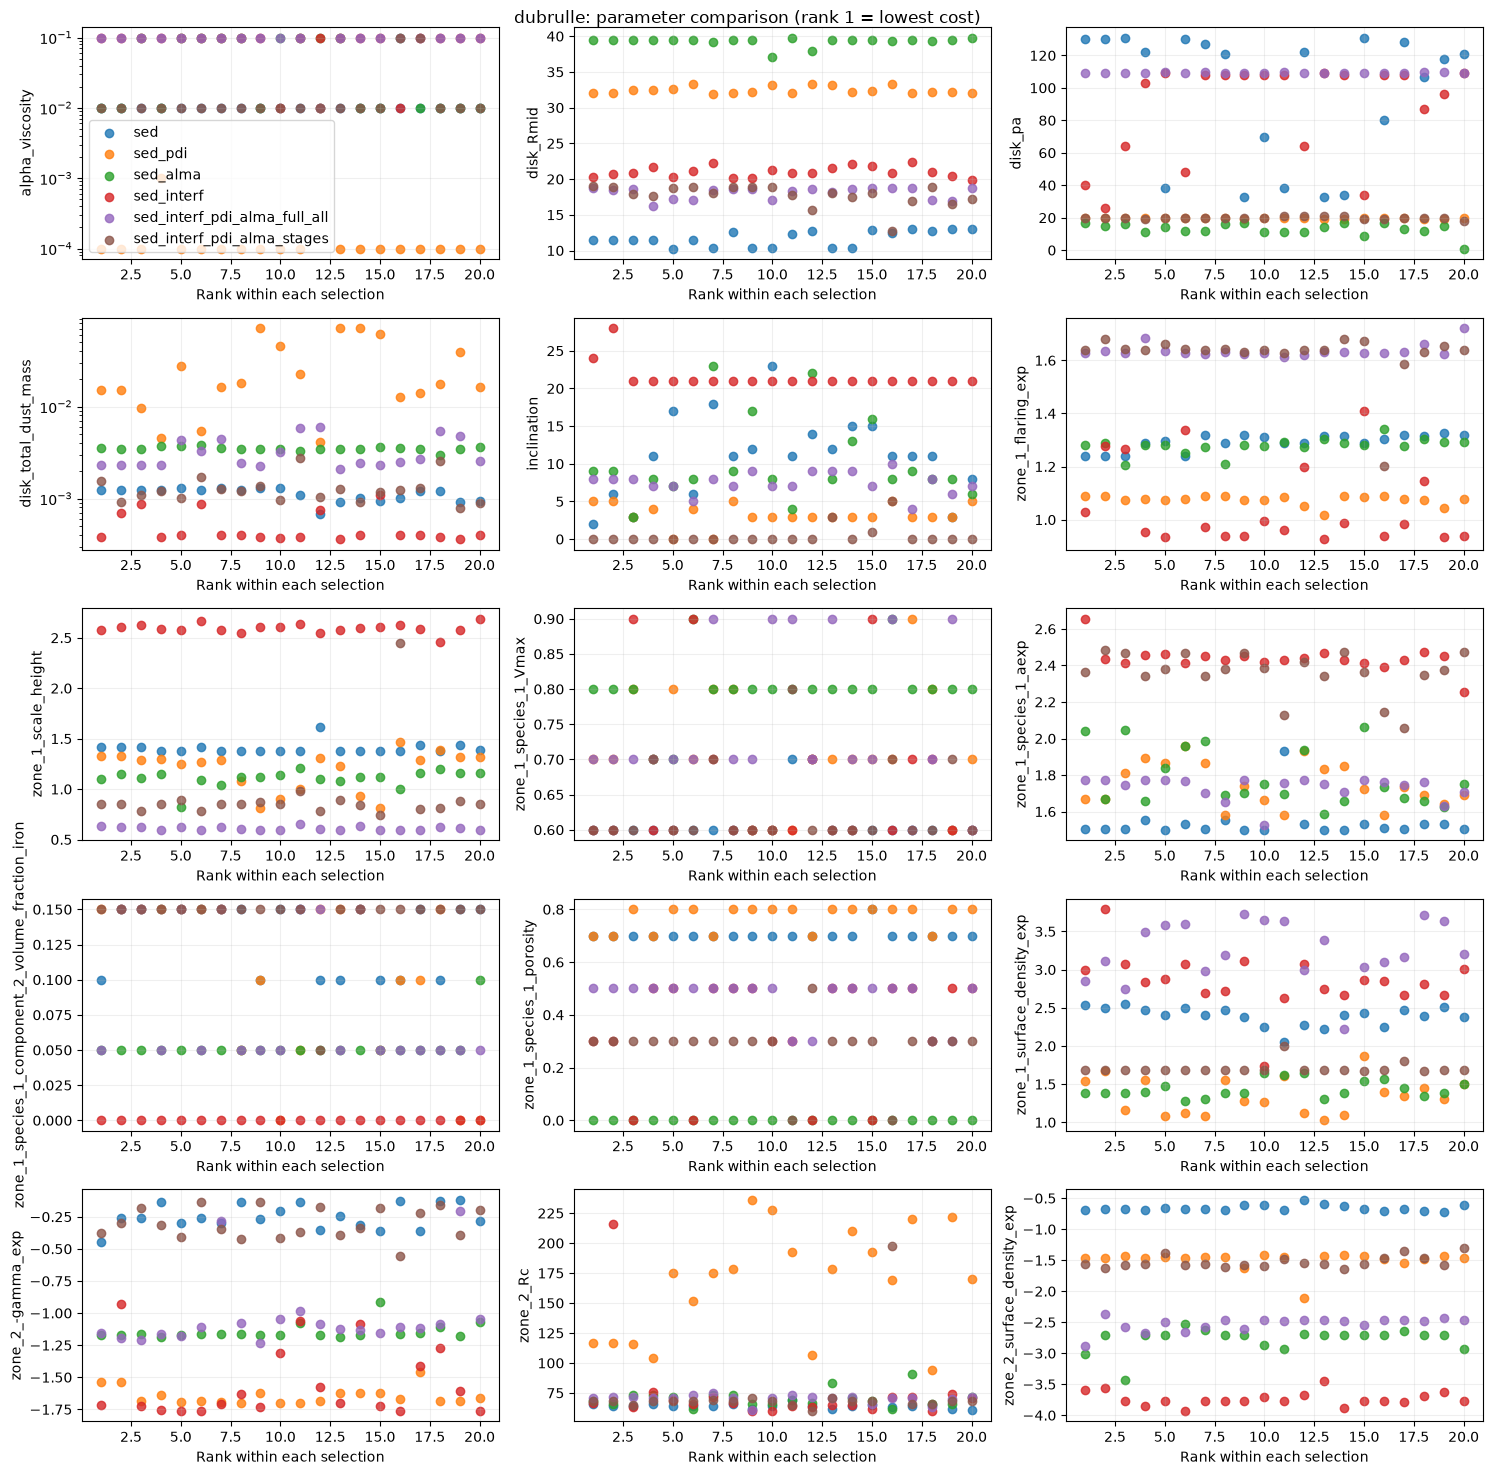

alpha_viscosity                disk_Rmid  \
                                         min  median   max        min   
prescription                                                            
sed                                   0.0100  0.0100  0.01  10.274708   
sed_alma                              0.0100  0.0550  0.10  37.133889   
sed_interf                            0.0100  0.1000  0.10  19.806208   
sed_interf_pdi_alma_full_all          0.0100  0.1000  0.10  16.167399   
sed_interf_pdi_alma_stages            0.0100  0.0100  0.10  12.709028   
sed_pdi                               0.0001  0.0001  0.01  31.949883   

                                                   disk_pa              \
                                 median        max     min median  max   
prescription                                                             
sed                           11.438133  13.026306      33  121.0  131   
sed_alma                      39.436725  39.810713       1   13.5   17   
sed_interf                    20.874557  22.401499      26  108.0  109   
sed_interf_pdi_alma_full_all  18.562840  18.735497     109  109.0  110   
sed_interf_pdi_alma_stages    18.002312  19.044252      18   20.0   21   
sed_pdi                       32.197602  33.367336      19   20.0   20   

                             disk_total_dust_mass  ...  \
                                              min  ...   
prescription                                       ...   
sed                                      0.000676  ...   
sed_alma                                 0.002980  ...   
sed_interf                               0.000362  ...   
sed_interf_pdi_alma_full_all             0.002105  ...   
sed_interf_pdi_alma_stages               0.000795  ...   
sed_pdi                                  0.004095  ...   

                             zone_1_surface_density_exp zone_2_-gamma_exp  \
                                                    max               min   
prescription                                                                
sed                                            2.550709         -0.444373   
sed_alma                                       1.644486         -1.186137   
sed_interf                                     3.789527         -1.762206   
sed_interf_pdi_alma_full_all                   3.729082         -1.235648   
sed_interf_pdi_alma_stages                     2.004439         -0.552914   
sed_pdi                                        1.868458         -1.702403   

                                                 zone_2_Rc              \
                                median       max       min median  max   
prescription                                                             
sed                          -0.261962 -0.119050        61   64.0   69   
sed_alma                     -1.167009 -0.914153        62   68.5   91   
sed_interf                   -1.707897 -0.929321        60   66.5  216   
sed_interf_pdi_alma_full_all -1.113528 -0.206077        61   71.0   75   
sed_interf_pdi_alma_stages   -0.325552 -0.136958        60   68.0  198   
sed_pdi                      -1.673872 -1.462725        94  175.0  236   

                             zone_2_surface_density_exp                      
                                                    min    median       max  
prescription                                                                 
sed                                           -0.719992 -0.673308 -0.527890  
sed_alma                                      -3.435479 -2.702480 -2.534590  
sed_interf                                    -3.930304 -3.771698 -3.449529  
sed_interf_pdi_alma_full_all                  -2.877700 -2.472756 -2.368153  
sed_interf_pdi_alma_stages                    -1.634580 -1.565449 -1.308737  
sed_pdi                                       -2.107968 -1.455391 -1.419476  

[6 rows x 45 columns]

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4))
for label, data in selections.items():
    ranks = np.arange(1, len(data) + 1)
    ax.plot(ranks, data['cost'], 'o-', label=label, color=COLORS[label])
ax.set(xlabel='Rank within each saved selection', ylabel='Cost',
       title=f'{RUN_NAME}: saved top configurations')
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(results_dir / 'top20_ranked_cost_comparison.png', dpi=150)
plt.show()
plt.close(fig)

plot_params = [p for p in param_cols
               if all(pd.api.types.is_numeric_dtype(data[p]) for data in selections.values())
               and combined[p].nunique() > 1]
log_params = {'disk_total_dust_mass', 'alpha_viscosity'}
if plot_params:
    ncols = 3
    nrows = int(np.ceil(len(plot_params) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(15, 3 * nrows), squeeze=False)
    for ax, parameter in zip(axes.flat, plot_params):
        for label, data in selections.items():
            ax.scatter(np.arange(1, len(data) + 1), data[parameter],
                       color=COLORS[label], label=label, alpha=0.8)
        ax.set(xlabel='Rank within each selection', ylabel=parameter)
        if parameter in log_params and combined[parameter].gt(0).all():
            ax.set_yscale('log')
        ax.grid(alpha=0.2)
    axes.flat[0].legend()
    for ax in list(axes.flat)[len(plot_params):]:
        ax.set_visible(False)
    fig.suptitle(f'{RUN_NAME}: parameter comparison (rank 1 = lowest cost)')
    fig.tight_layout()
    fig.savefig(results_dir / 'top20_parameters_comparison.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(fig)

parameter_summary = combined.groupby('prescription')[plot_params].agg(['min', 'median', 'max'])
display(parameter_summary)
parameter_summary.to_csv(results_dir / 'parameter_summary.csv')


## Parameter spread by model
Violin widths show a smoothed density of the saved optimisation samples. Points retain individual values; white dots and black bars mark medians and interquartile ranges. Positive mass and viscosity parameters use logarithmic density and axes. Constant samples are shown as points without a violin.

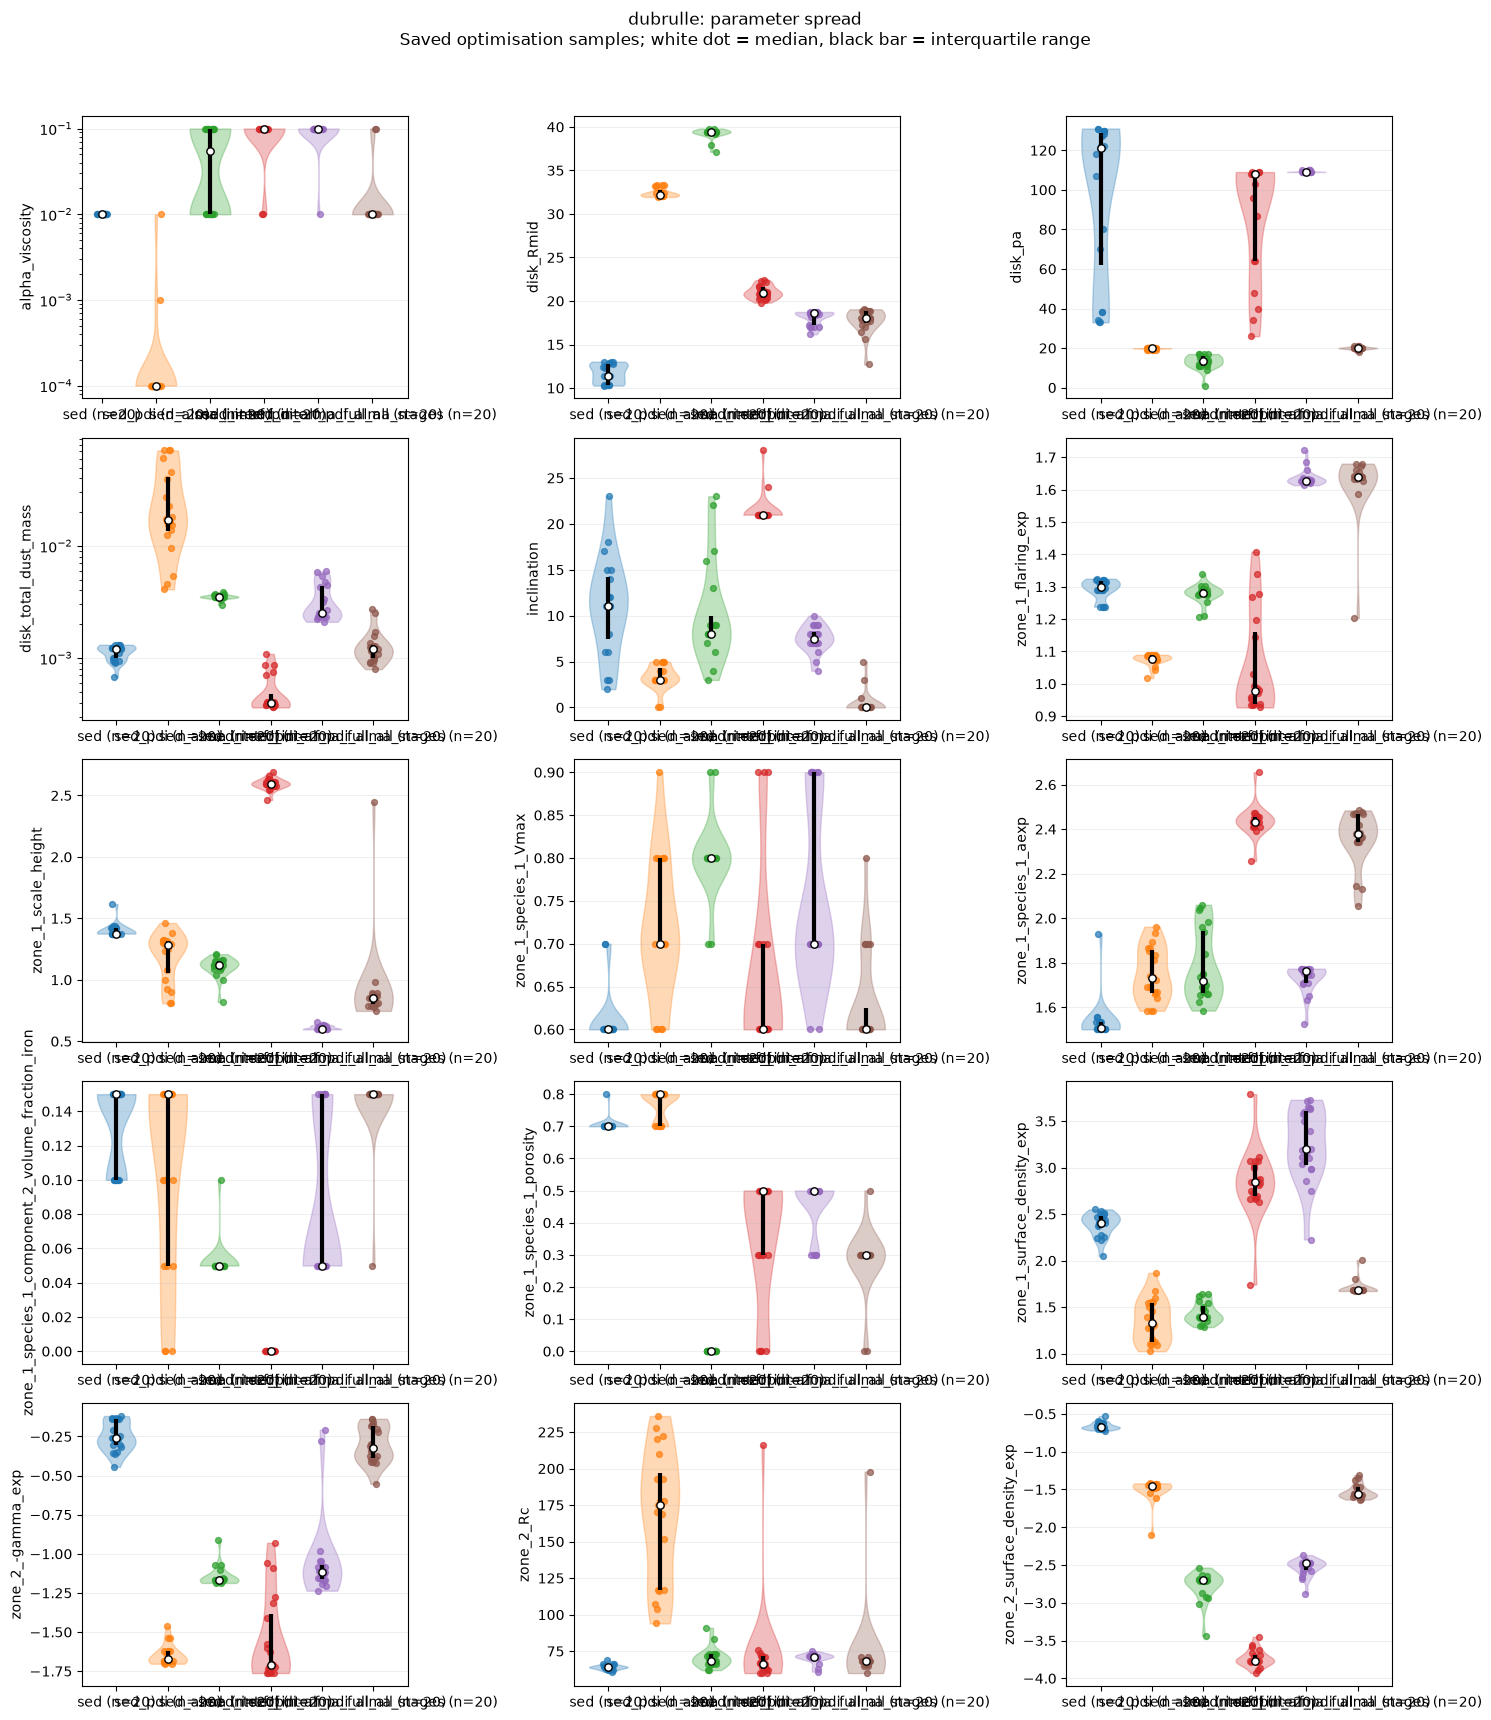

In [ ]:
# Compare parameter spread in each settling model.
# KDE is evaluated in log10 space for the existing logarithmic parameters.
violin_params = [p for p in plot_params if all(
    np.isfinite(data[p].to_numpy(dtype=float)).any() for data in selections.values())]
if violin_params:
    labels = list(selections)
    ncols = 3
    nrows = int(np.ceil(len(violin_params) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(15, 3.5 * nrows), squeeze=False)
    rng = np.random.default_rng(42)
    for ax, parameter in zip(axes.flat, violin_params):
        use_log = parameter in log_params and combined[parameter].dropna().gt(0).all()
        for position, label in enumerate(labels, start=1):
            values = selections[label][parameter].to_numpy(dtype=float)
            values = values[np.isfinite(values)]
            density_values = np.log10(values) if use_log else values
            # Constant or single-valued samples cannot define a KDE.
            if len(values) > 1 and np.unique(density_values).size > 1:
                parts = ax.violinplot([density_values], positions=[position],
                                      widths=0.75, showextrema=False)
                body = parts['bodies'][0]
                if use_log:
                    for path in body.get_paths():
                        path.vertices[:, 1] = 10 ** path.vertices[:, 1]
                body.set_facecolor(COLORS[label])
                body.set_edgecolor(COLORS[label])
                body.set_alpha(0.3)
            jitter = rng.uniform(-0.10, 0.10, len(values))
            ax.scatter(position + jitter, values, s=18, alpha=0.7,
                       color=COLORS[label], zorder=3)
            q1, median, q3 = np.percentile(values, [25, 50, 75])
            ax.vlines(position, q1, q3, color='black', linewidth=3, zorder=4)
            ax.scatter([position], [median], s=28, color='white',
                       edgecolor='black', zorder=5)
        ax.set_xticks(range(1, len(labels) + 1))
        ax.set_xticklabels([f'{label} (n={np.isfinite(selections[label][parameter].to_numpy(dtype=float)).sum()})'
                            for label in labels])
        ax.set_ylabel(parameter)
        if use_log:
            ax.set_yscale('log')
        ax.grid(axis='y', alpha=0.2)
    for ax in list(axes.flat)[len(violin_params):]:
        ax.set_visible(False)
    fig.suptitle(f'{RUN_NAME}: parameter spread\n'
                 'Saved optimisation samples; white dot = median, black bar = interquartile range',
                 fontsize=12)
    fig.tight_layout(rect=(0, 0, 1, 0.96))
    for extension in ('png', 'pdf'):
        fig.savefig(results_dir / f'top20_parameter_violins.{extension}',
                    dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(fig)


## Comparison of different modellings

In [ ]:
"""Read saved SMAC histories only; write comparison tables and figures beside this script."""
import collections
import csv
import hashlib
import json
import math
import os
from pathlib import Path

import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import spearmanr

ROOT = Path('/fred/oz061/kandrych/smac/1_akke_2zones_wider_tapered/fromang')
OUT = ROOT / 'model_comparison'
os.makedirs(OUT, exist_ok=True)

def write_csv(name, rows):
    keys = list(dict.fromkeys(k for r in rows for k in r))
    with (OUT / name).open('w', newline='') as f:
        w = csv.DictWriter(f, fieldnames=keys)
        w.writeheader()
        w.writerows(rows)

def valid(r):
    return (r['status'] == 1 and isinstance(r['cost'], (int, float))
            and math.isfinite(r['cost']) and r['cost'] < 1e90
            and not (r.get('additional_info') or {}).get('failure'))

def terms(r):
    a = r.get('additional_info') or {}
    result = {'sed': a.get('sed', {}).get('chi2_reduced')}
    for name in ('pionier', 'gravity', 'matisse_l', 'matisse_n'):
        result[name] = a.get('vis2_1perband', {}).get(name, {}).get('chi2_reduced')
    for band in ('V', 'I', 'H'):
        result['pdi_' + band] = a.get('pdi', {}).get(band, {}).get('loss')
    result['alma'] = a.get('alma', {}).get('loss')
    return result

def subsets(r):
    t = terms(r)
    s = t['sed']
    it = sum(t[k] for k in ('pionier', 'gravity', 'matisse_l', 'matisse_n'))
    pd = sum(t['pdi_' + b] for b in ('V', 'I', 'H'))
    return {'SED': s, 'SED+ALMA': s+t['alma'], 'SED+interferometry': s+it,
            'SED+PDI': s+pd, 'ALL': s+it+pd+t['alma']}

histories, flat, winners, summaries, correlations, ranges = [], [], [], [], [], []
for path in sorted(ROOT.glob('*/optimization/*/runhistory.json')):
    raw = path.read_bytes()
    d = json.loads(raw)
    run, seed = path.parts[-4], path.parts[-2]
    good = [r for r in d['data'] if valid(r)]
    histories.append((path, d, good))
    max_budget = max(r['budget'] for r in good)
    groups = {}
    for r in d['data']:
        cfg = d['configs'][str(r['config_id'])]
        row = {'run': run, 'optimizer_seed': seed, 'config_id': r['config_id'],
               'simulation_seed': r.get('seed'), 'budget': r['budget'],
               'status': r['status'], 'valid': valid(r), 'cost': r['cost'],
               'runtime_seconds': r.get('time'),
               'parameter_hash': hashlib.sha256(json.dumps(cfg, sort_keys=True).encode()).hexdigest(),
               'failure_reason': (r.get('additional_info') or {}).get('failure', {}).get('reason', '')}
        row.update(terms(r))
        row.update(cfg)
        flat.append(row)
        if valid(r):
            assert math.isclose(sum(x for x in terms(r).values() if x is not None),
                                r['cost'], rel_tol=1e-9, abs_tol=1e-8), (path, r['config_id'])
            groups.setdefault(r['budget'], {})[(r['config_id'], r.get('seed'), r.get('instance'))] = r
    for b in sorted({r['budget'] for r in d['data']}):
        rows = [r for r in d['data'] if r['budget'] == b]
        usable = [r for r in rows if valid(r)]
        summaries.append({'run': run, 'optimizer_seed': seed, 'budget': b,
                          'recorded': len(rows), 'usable': len(usable),
                          'penalties_or_failures': sum(bool((r.get('additional_info') or {}).get('failure')) or
                                                      (isinstance(r['cost'], (int,float)) and r['cost'] >= 1e90) for r in rows),
                          'unfinished': sum(r['status'] == 0 for r in rows),
                          'best_cost': min((r['cost'] for r in usable), default=None),
                          'history_sha256': hashlib.sha256(raw).hexdigest()})
    best = min((r for r in good if r['budget'] == max_budget), key=lambda r:r['cost'])
    winners.append((run, seed, best, d['configs'][str(best['config_id'])]))
    near = [r for r in good if r['budget'] == max_budget and r['cost'] <= 1.1*best['cost']]
    for key in ('disk_Rmid', 'disk_total_dust_mass', 'inclination', 'disk_pa', 'zone_2_Rc',
                'zone_1_scale_height', 'zone_1_flaring_exp', 'alpha_viscosity'):
        values = [d['configs'][str(r['config_id'])][key] for r in near]
        ranges.append({'run':run, 'optimizer_seed':seed, 'selection':'cost <= 1.1 * best; exploratory, not confidence interval',
                       'count':len(near), 'parameter':key, 'min':min(values), 'max':max(values)})
    for low, high in zip(sorted(groups), sorted(groups)[1:]):
        shared = set(groups[low]) & set(groups[high])
        correlations.append({'run':run, 'optimizer_seed':seed, 'low_budget':low, 'high_budget':high,
                             'paired_evaluations':len(shared), 'spearman_rho':float(spearmanr(
                                 [groups[low][k]['cost'] for k in shared], [groups[high][k]['cost'] for k in shared]).statistic),
                             'scope':'paired sampled configurations; selection biased'})
write_csv('evaluations.csv', flat)
write_csv('stage_summary.csv', summaries)
write_csv('stage_rank_correlations.csv', correlations)
write_csv('competitive_parameter_ranges.csv', ranges)
write_csv('best_models.csv', [dict(run=run, optimizer_seed=seed, config_id=r['config_id'], budget=r['budget'],
                                  cost=r['cost'], **terms(r), **cfg) for run,seed,r,cfg in winners])

pool = [(p.parts[-4], p.parts[-2], r, d['configs'][str(r['config_id'])])
        for p,d,good in histories for r in good
        if 'pdi' in r['additional_info'] and 'alma' in r['additional_info']]
subset_rows = []
for objective in subsets(pool[0][2]):
    run,seed,r,cfg = min(pool, key=lambda t:subsets(t[2])[objective])
    subset_rows.append(dict(objective=objective, run=run, optimizer_seed=seed,
                            config_id=r['config_id'], budget=r['budget'], pool_evaluations=len(pool), **subsets(r)))
write_csv('common_pool_subset_winners.csv', subset_rows)

chosen = [w for w in winners if w[1] != '167697']
labels = {'sed':'SED', 'sed_alma':'SED + ALMA', 'sed_interf':'SED + interferometry',
          'sed_pdi':'SED + PDI', 'sed_interf_pdi_alma_full_all':'All: direct (426447)',
          'sed_interf_pdi_alma_stages':'All: staged (2692)'}
fig, ax = plt.subplots(figsize=(11, 5.2), layout='constrained')
left = np.zeros(len(chosen))
components = [('sed','SED','#4c78a8'), ('pionier','PIONIER','#72b7b2'), ('gravity','GRAVITY','#54a24b'),
              ('matisse_l','MATISSE L','#eeca3b'), ('matisse_n','MATISSE N','#b79a20'),
              ('pdi_V','PDI V','#f58518'), ('pdi_I','PDI I','#e45756'), ('pdi_H','PDI H','#b279a2'),
              ('alma','ALMA','#777777')]
for key,label,color in components:
    values = np.array([terms(w[2])[key] or 0 for w in chosen])
    ax.barh(range(len(chosen)), values, left=left, label=label, color=color)
    left += values
for i,total in enumerate(left): ax.text(total+3, i, f'{total:.2f}', va='center', fontsize=9)
ax.set_yticks(range(len(chosen)), [labels[w[0]] for w in chosen])
ax.invert_yaxis()
ax.set_xlim(0, max(left)*1.16)
ax.set_xlabel('Recorded composite objective (lower is better; not joint reduced chi-square)')
ax.set_title('Best recorded models: contribution of each observation group')
ax.legend(ncol=5, loc='upper center', bbox_to_anchor=(0.5,-0.14), frameon=False)
ax.text(0,-0.32,'Missing observation groups are unscored, not zero residual. Excludes penalty and unfinished trials.',
        transform=ax.transAxes, fontsize=9)
fig.savefig(OUT/'score_comparison.png', dpi=180)
plt.close(fig)

joint = [w for w in chosen if w[0] in ('sed_interf_pdi_alma_full_all','sed_interf_pdi_alma_stages')]
fig, axes = plt.subplots(1,2,figsize=(11,4.5),layout='constrained')
for run,seed,r,cfg in joint:
    ratios = [r['additional_info']['pdi'][b]['constraints']['model']['positive_qphi_over_i']/
              r['additional_info']['pdi'][b]['constraints']['observed']['positive_qphi_over_i'] for b in ('V','I','H')]
    axes[0].plot(['V','I','H'],ratios,marker='o',label=labels[run])
axes[0].axhline(1,color='black',linestyle='--',label='Observed')
axes[0].set_yscale('log');axes[0].set_ylabel('Model / observed positive Qphi-to-I fraction')
axes[0].set_title('PDI amplitude mismatch');axes[0].legend(fontsize=8)
alma_models = [w for w in chosen if w[2]['additional_info'].get('alma')]
values = [w[2]['additional_info']['alma']['comparison']['model_to_observed_flux'] for w in alma_models]
axes[1].barh([labels[w[0]] for w in alma_models],values,color=['#777777','#4c78a8','#f58518'])
axes[1].axvline(1,color='black',linestyle='--'); axes[1].set_xlim(0,1.1)
axes[1].set_xlabel('Model / observed aperture flux');axes[1].set_title('ALMA aperture flux')
for i,v in enumerate(values):axes[1].text(v+0.02,i,f'{v:.3f}',va='center')
fig.savefig(OUT/'prediction_amplitudes.png',dpi=180)
display(fig)
plt.close(fig)
print(json.dumps({'output_directory':str(OUT),'histories':len(histories),'recorded_evaluations':len(flat),
                  'common_pool_evaluations':len(pool),'figure_count':2,'tables':6}))


<Figure size 1100x450 with 2 Axes>

{"output_directory": "/fred/oz061/kandrych/smac/1_akke_2zones_wider_tapered/fromang/model_comparison", "histories": 6, "recorded_evaluations": 8003, "common_pool_evaluations": 1450, "figure_count": 2, "tables": 6}
